In [1]:
import os


In [2]:
os.listdir()

['.ipynb_checkpoints',
 'Bookstore_Inventory_Analytics.ipynb',
 'inventory.csv',
 'sales.csv']

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
inventory_df = pd.read_csv("inventory.csv")
sales_df = pd.read_csv("sales.csv")

In [5]:
inventory_df.head()

,Book_ID,Title,Author,Category,Publisher,Price,Stock_Quantity,Reorder_Level,Publication_Year
0,B001,Non-Fiction Book 1,S. Mehta,Non-Fiction,HarperCollins,201,35,10,2008
1,B002,Non-Fiction Book 2,A. Sharma,Non-Fiction,Penguin,1014,4,10,2012
2,B003,Fiction Book 3,N. Joshi,Fiction,HarperCollins,557,69,20,2023
3,B004,Business Book 4,N. Joshi,Business,Oxford Press,163,20,15,2009
4,B005,Technology Book 5,R. Patel,Technology,Pearson,839,13,5,2016


In [6]:
inventory_df.shape

(100, 9)

In [7]:
inventory_df.columns

Index(['Book_ID', 'Title', 'Author', 'Category', 'Publisher', 'Price',
       'Stock_Quantity', 'Reorder_Level', 'Publication_Year'],
      dtype='str')

In [8]:
sales_df.columns

Index(['Sale_ID', 'Date', 'Book_ID', 'Quantity_Sold', 'Unit_Price',
       'Discount_Percent', 'Total_Amount', 'Payment_Method', 'Customer_Type'],
      dtype='str')

In [9]:
inventory_df.isnull().sum()

Book_ID             0
Title               0
Author              0
Category            0
Publisher           0
Price               0
Stock_Quantity      0
Reorder_Level       0
Publication_Year    0
dtype: int64

In [10]:
sales_df.isnull().sum()

Sale_ID             0
Date                0
Book_ID             0
Quantity_Sold       0
Unit_Price          0
Discount_Percent    0
Total_Amount        0
Payment_Method      0
Customer_Type       0
dtype: int64

In [11]:
inventory_df.dtypes

Book_ID               str
Title                 str
Author                str
Category              str
Publisher             str
Price               int64
Stock_Quantity      int64
Reorder_Level       int64
Publication_Year    int64
dtype: object

In [12]:
sales_df.dtypes

Sale_ID                 str
Date                    str
Book_ID                 str
Quantity_Sold         int64
Unit_Price            int64
Discount_Percent      int64
Total_Amount        float64
Payment_Method          str
Customer_Type           str
dtype: object

In [13]:
sales_df["Date"] = pd.to_datetime(sales_df["Date"])

In [14]:
sales_df.dtypes

Sale_ID                        str
Date                datetime64[us]
Book_ID                        str
Quantity_Sold                int64
Unit_Price                   int64
Discount_Percent             int64
Total_Amount               float64
Payment_Method                 str
Customer_Type                  str
dtype: object

In [15]:
print("Duplicate inventory records:", inventory_df.duplicated().sum())
print("Duplicate sales records:", sales_df.duplicated().sum())

Duplicate inventory records: 0
Duplicate sales records: 0


In [17]:
inventory_df.describe()

,Price,Stock_Quantity,Reorder_Level,Publication_Year
count,100.000000,100.000000,100.000000,100.000000
mean,662.780000,43.200000,11.750000,2014.300000
std,287.429204,20.992062,5.335937,6.129083
min,163.000000,0.000000,5.000000,2005.000000
25%,425.750000,29.000000,5.000000,2009.000000
50%,640.000000,46.000000,10.000000,2013.000000
75%,917.000000,59.000000,15.000000,2019.000000
max,1196.000000,80.000000,20.000000,2026.000000


In [18]:
sales_df.describe()

,Date,Quantity_Sold,Unit_Price,Discount_Percent,Total_Amount
count,200,200.000000,200.00000,200.000000,200.00000
mean,2026-05-30 09:00:00,3.070000,690.46500,6.500000,1969.27725
min,2026-01-01 00:00:00,1.000000,163.00000,0.000000,204.25000
25%,2026-03-10 12:00:00,2.000000,480.00000,0.000000,988.55000
50%,2026-06-02 12:00:00,3.000000,647.00000,5.000000,1642.50000
75%,2026-08-20 06:00:00,4.000000,926.00000,10.000000,2640.52500
max,2026-10-23 00:00:00,5.000000,1196.00000,15.000000,5681.00000
std,NaN,1.365438,294.43947,5.802443,1273.44873


In [19]:
class Bookstore:
    
    def __init__(self, inventory, sales):
        self.inventory = inventory
        self.sales = sales

In [20]:
bookstore = Bookstore(inventory_df, sales_df)

In [21]:
print("Total books:", len(bookstore.inventory))
print("Total sales records:", len(bookstore.sales))

Total books: 100
Total sales records: 200


In [22]:
class Bookstore:
    
    def __init__(self, inventory, sales):
        self.inventory = inventory
        self.sales = sales
    
    def view_inventory(self):
        return self.inventory

In [23]:
bookstore = Bookstore(inventory_df, sales_df)

In [24]:
bookstore.view_inventory()

,Book_ID,Title,Author,Category,Publisher,Price,Stock_Quantity,Reorder_Level,Publication_Year
0,B001,Non-Fiction Book 1,S. Mehta,Non-Fiction,HarperCollins,201,35,10,2008
1,B002,Non-Fiction Book 2,A. Sharma,Non-Fiction,Penguin,1014,4,10,2012
2,B003,Fiction Book 3,N. Joshi,Fiction,HarperCollins,557,69,20,2023
3,B004,Business Book 4,N. Joshi,Business,Oxford Press,163,20,15,2009
4,B005,Technology Book 5,R. Patel,Technology,Pearson,839,13,5,2016
...,...,...,...,...,...,...,...,...,...
95,B096,Education Book 96,D. Singh,Education,Pearson,642,60,5,2007
96,B097,Business Book 97,S. Mehta,Business,Oxford Press,603,51,15,2020
97,B098,History Book 98,K. Verma,History,Oxford Press,1021,70,20,2013
98,B099,Business Book 99,R. Patel,Business,Rupa Publications,664,29,10,2015


In [43]:
class Bookstore:

    def __init__(self, inventory, sales):
        self.inventory = inventory
        self.sales = sales

    def view_inventory(self):
        return self.inventory

    def add_book(self):
        print("========== ADD NEW BOOK ==========")

        book_id = input("Enter Book ID: ")
        title = input("Enter Book Title: ")
        author = input("Enter Author: ")
        category = input("Enter Category: ")
        publisher = input("Enter Publisher: ")

        try:
            price = float(input("Enter Price: "))
            stock = int(input("Enter Stock Quantity: "))
            reorder_level = int(input("Enter Reorder Level: "))
            publication_year = int(input("Enter Publication Year: "))
        except ValueError:
            print("Invalid input! Please enter valid numbers.")
            return

        if price <= 0:
            print("Price must be greater than 0.")
            return

        if stock < 0:
            print("Stock quantity cannot be negative.")
            return

        if reorder_level < 0:
            print("Reorder level cannot be negative.")
            return

        if book_id in self.inventory["Book_ID"].astype(str).values:
            print("Book ID already exists.")
            return

        new_book = {
            "Book_ID": book_id,
            "Title": title,
            "Author": author,
            "Category": category,
            "Publisher": publisher,
            "Price": price,
            "Stock_Quantity": stock,
            "Reorder_Level": reorder_level,
            "Publication_Year": publication_year
        }

        self.inventory = pd.concat(
            [self.inventory, pd.DataFrame([new_book])],
            ignore_index=True
        )

        print("Book added successfully!")

    def update_inventory(self):
        print("========== UPDATE INVENTORY ==========")

        book_id = input("Enter Book ID: ")

        matching_books = self.inventory[
            self.inventory["Book_ID"].astype(str) == book_id
        ]

        if matching_books.empty:
            print("Book not found.")
            return

        try:
            new_quantity = int(input("Enter new stock quantity: "))
        except ValueError:
            print("Please enter a valid number.")
            return

        if new_quantity < 0:
            print("Stock quantity cannot be negative.")
            return

        self.inventory.loc[
            self.inventory["Book_ID"].astype(str) == book_id,
            "Stock_Quantity"
        ] = new_quantity

        print("Inventory updated successfully!")

    def check_low_stock(self):
        low_stock = self.inventory[
            self.inventory["Stock_Quantity"] <= self.inventory["Reorder_Level"]
        ]

        if low_stock.empty:
            print("No books need to be reordered.")
        else:
            print("========== LOW STOCK BOOKS ==========")
            print(
                low_stock[
                    ["Book_ID", "Title", "Stock_Quantity", "Reorder_Level"]
                ]
            )

    def record_sale(self):
        print("========== RECORD SALE ==========")

        book_id = input("Enter Book ID: ")

        matching_books = self.inventory[
            self.inventory["Book_ID"].astype(str) == book_id
        ]

        if matching_books.empty:
            print("Book not found.")
            return

        book_index = matching_books.index[0]

        title = self.inventory.loc[book_index, "Title"]
        price = float(self.inventory.loc[book_index, "Price"])
        available_stock = int(self.inventory.loc[book_index, "Stock_Quantity"])

        print("Book:", title)
        print("Price:", price)
        print("Available Stock:", available_stock)

        try:
            quantity_sold = int(input("Enter Quantity Sold: "))
            discount = float(input("Enter Discount Percentage: "))
        except ValueError:
            print("Please enter valid numbers.")
            return

        if quantity_sold <= 0:
            print("Quantity sold must be greater than 0.")
            return

        if quantity_sold > available_stock:
            print("Insufficient stock!")
            return

        if discount < 0 or discount > 100:
            print("Discount must be between 0 and 100.")
            return

        gross_amount = price * quantity_sold
        discount_amount = gross_amount * (discount / 100)
        total_amount = gross_amount - discount_amount

        new_stock = available_stock - quantity_sold

        self.inventory.loc[
            book_index, "Stock_Quantity"
        ] = new_stock

        sale_id = "S" + str(len(self.sales) + 1)

        new_sale = {
            "Sale_ID": sale_id,
            "Date": pd.Timestamp.today(),
            "Book_ID": book_id,
            "Quantity_Sold": quantity_sold,
            "Unit_Price": price,
            "Discount_Percent": discount,
            "Total_Amount": total_amount,
            "Payment_Method": "Cash",
            "Customer_Type": "Regular"
        }

        self.sales = pd.concat(
            [self.sales, pd.DataFrame([new_sale])],
            ignore_index=True
        )

        print("\nSale recorded successfully!")
        print("Book:", title)
        print("Quantity Sold:", quantity_sold)
        print("Discount:", discount, "%")
        print("Total Amount:", round(total_amount, 2))
        print("Remaining Stock:", new_stock)

    def generate_report(self):
        print("\n========== BOOKSTORE REPORT ==========")

        total_books = len(self.inventory)
        total_stock = np.sum(self.inventory["Stock_Quantity"])
        total_sales = len(self.sales)
        total_quantity_sold = np.sum(self.sales["Quantity_Sold"])
        total_revenue = np.sum(self.sales["Total_Amount"])
        average_price = np.mean(self.inventory["Price"])

        best_selling = (
            self.sales.groupby("Book_ID")["Quantity_Sold"]
            .sum()
            .sort_values(ascending=False)
        )

        if not best_selling.empty:
            best_book_id = best_selling.index[0]

            matching_book = self.inventory[
                self.inventory["Book_ID"].astype(str) == str(best_book_id)
            ]

            if not matching_book.empty:
                best_book_title = matching_book.iloc[0]["Title"]
            else:
                best_book_title = "Unknown"
        else:
            best_book_title = "No sales yet"

        low_stock_count = np.sum(
            self.inventory["Stock_Quantity"] <= self.inventory["Reorder_Level"]
        )

        print("Total Books:", total_books)
        print("Total Stock:", total_stock)
        print("Total Sales Transactions:", total_sales)
        print("Total Quantity Sold:", total_quantity_sold)
        print("Total Revenue: ₹", round(total_revenue, 2))
        print("Average Book Price: ₹", round(average_price, 2))
        print("Best-Selling Book:", best_book_title)
        print("Low-Stock Books:", low_stock_count)

In [33]:
bookstore = Bookstore(inventory_df, sales_df)

In [27]:
bookstore.add_book()

========== ADD NEW BOOK ==========


Enter Book ID:  B101
Enter Book Title:  the power of now
Enter Author:  eckhart tolle
Enter Category:  self help
Enter Publisher:  penguin
Enter Price:  450
Enter Stock Quantity:  10
Enter Reorder Level:  3
Enter Publication Year:  1997


Book added successfully!


In [28]:
bookstore.inventory.tail()

,Book_ID,Title,Author,Category,Publisher,Price,Stock_Quantity,Reorder_Level,Publication_Year
96,B097,Business Book 97,S. Mehta,Business,Oxford Press,603.0,51,15,2020
97,B098,History Book 98,K. Verma,History,Oxford Press,1021.0,70,20,2013
98,B099,Business Book 99,R. Patel,Business,Rupa Publications,664.0,29,10,2015
99,B100,Non-Fiction Book 100,S. Mehta,Non-Fiction,Rupa Publications,529.0,24,20,2013
100,B101,the power of now,eckhart tolle,self help,penguin,450.0,10,3,1997


In [29]:
    def update_inventory(self):
        print("========== UPDATE INVENTORY ==========")
        
        book_id = input("Enter Book ID: ")
        
        matching_books = self.inventory[
            self.inventory["Book_ID"].astype(str) == book_id
        ]
        
        if matching_books.empty:
            print("Book not found.")
            return
        
        try:
            new_quantity = int(input("Enter new stock quantity: "))
        except ValueError:
            print("Please enter a valid number.")
            return
        
        if new_quantity < 0:
            print("Stock quantity cannot be negative.")
            return
        
        self.inventory.loc[
            self.inventory["Book_ID"].astype(str) == book_id,
            "Stock_Quantity"
        ] = new_quantity
        
        print("Inventory updated successfully!")

In [30]:
bookstore = Bookstore(inventory_df, sales_df)

In [34]:
bookstore.update_inventory()

========== UPDATE INVENTORY ==========


Enter Book ID:  B001
Enter new stock quantity:  20


Inventory updated successfully!


In [38]:
bookstore = Bookstore(inventory_df, sales_df)

In [39]:
bookstore.record_sale()

========== RECORD SALE ==========


Enter Book ID:  B001


Book: Non-Fiction Book 1
Price: 201.0
Available Stock: 20


Enter Quantity Sold:  2
Enter Discount Percentage:  10



Sale recorded successfully!
Book: Non-Fiction Book 1
Quantity Sold: 2
Discount: 10.0 %
Total Amount: 361.8
Remaining Stock: 18


In [40]:
bookstore.sales.tail()

,Sale_ID,Date,Book_ID,Quantity_Sold,Unit_Price,Discount_Percent,Total_Amount,Payment_Method,Customer_Type
196,S0197,2026-07-23 00:00:00.000000,B012,1,215.0,5.0,204.25,Net Banking,Student
197,S0198,2026-02-07 00:00:00.000000,B053,4,512.0,15.0,1740.80,UPI,New
198,S0199,2026-08-27 00:00:00.000000,B083,1,866.0,10.0,779.40,Card,Regular
199,S0200,2026-04-04 00:00:00.000000,B100,5,529.0,15.0,2248.25,UPI,New
200,S201,2026-10-23 17:09:28.758146,B001,2,201.0,10.0,361.80,Cash,Regular


In [41]:
bookstore.inventory[
    bookstore.inventory["Book_ID"].astype(str) == "B001"
]

,Book_ID,Title,Author,Category,Publisher,Price,Stock_Quantity,Reorder_Level,Publication_Year
0,B001,Non-Fiction Book 1,S. Mehta,Non-Fiction,HarperCollins,201,18,10,2008


In [44]:
bookstore.generate_report()

AttributeError: 'Bookstore' object has no attribute 'generate_report'

In [45]:
bookstore = Bookstore(inventory_df, sales_df)

In [46]:
bookstore.generate_report()


========== BOOKSTORE REPORT ==========
Total Books: 100
Total Stock: 4303
Total Sales Transactions: 200
Total Quantity Sold: 614
Total Revenue: ₹ 393855.45
Average Book Price: ₹ 662.78
Best-Selling Book: History Book 89
Low-Stock Books: 10


In [47]:
class Bookstore:

    def __init__(self, inventory, sales):
        self.inventory = inventory
        self.sales = sales

    # ---------------- VIEW INVENTORY ----------------
    def view_inventory(self):
        return self.inventory

    # ---------------- ADD BOOK ----------------
    def add_book(self):
        print("========== ADD NEW BOOK ==========")

        book_id = input("Enter Book ID: ")
        title = input("Enter Book Title: ")
        author = input("Enter Author: ")
        category = input("Enter Category: ")
        publisher = input("Enter Publisher: ")

        try:
            price = float(input("Enter Price: "))
            stock = int(input("Enter Stock Quantity: "))
            reorder_level = int(input("Enter Reorder Level: "))
            publication_year = int(input("Enter Publication Year: "))
        except ValueError:
            print("Invalid input! Please enter valid numbers.")
            return

        if price <= 0:
            print("Price must be greater than 0.")
            return

        if stock < 0:
            print("Stock quantity cannot be negative.")
            return

        if reorder_level < 0:
            print("Reorder level cannot be negative.")
            return

        if book_id in self.inventory["Book_ID"].astype(str).values:
            print("Book ID already exists.")
            return

        new_book = {
            "Book_ID": book_id,
            "Title": title,
            "Author": author,
            "Category": category,
            "Publisher": publisher,
            "Price": price,
            "Stock_Quantity": stock,
            "Reorder_Level": reorder_level,
            "Publication_Year": publication_year
        }

        self.inventory = pd.concat(
            [self.inventory, pd.DataFrame([new_book])],
            ignore_index=True
        )

        print("Book added successfully!")

    # ---------------- UPDATE INVENTORY ----------------
    def update_inventory(self):
        print("========== UPDATE INVENTORY ==========")

        book_id = input("Enter Book ID: ")

        matching_books = self.inventory[
            self.inventory["Book_ID"].astype(str) == book_id
        ]

        if matching_books.empty:
            print("Book not found.")
            return

        try:
            new_quantity = int(input("Enter new stock quantity: "))
        except ValueError:
            print("Please enter a valid number.")
            return

        if new_quantity < 0:
            print("Stock quantity cannot be negative.")
            return

        self.inventory.loc[
            self.inventory["Book_ID"].astype(str) == book_id,
            "Stock_Quantity"
        ] = new_quantity

        print("Inventory updated successfully!")

    # ---------------- LOW STOCK ----------------
    def check_low_stock(self):
        low_stock = self.inventory[
            self.inventory["Stock_Quantity"]
            <= self.inventory["Reorder_Level"]
        ]

        if low_stock.empty:
            print("No books need to be reordered.")
        else:
            print("========== LOW STOCK BOOKS ==========")

            print(
                low_stock[
                    [
                        "Book_ID",
                        "Title",
                        "Stock_Quantity",
                        "Reorder_Level"
                    ]
                ]
            )

    # ---------------- RECORD SALE ----------------
    def record_sale(self):
        print("========== RECORD SALE ==========")

        book_id = input("Enter Book ID: ")

        matching_books = self.inventory[
            self.inventory["Book_ID"].astype(str) == book_id
        ]

        if matching_books.empty:
            print("Book not found.")
            return

        book_index = matching_books.index[0]

        title = self.inventory.loc[book_index, "Title"]
        price = float(self.inventory.loc[book_index, "Price"])
        available_stock = int(
            self.inventory.loc[book_index, "Stock_Quantity"]
        )

        print("Book:", title)
        print("Price:", price)
        print("Available Stock:", available_stock)

        try:
            quantity_sold = int(input("Enter Quantity Sold: "))
            discount = float(
                input("Enter Discount Percentage: ")
            )
        except ValueError:
            print("Please enter valid numbers.")
            return

        if quantity_sold <= 0:
            print("Quantity sold must be greater than 0.")
            return

        if quantity_sold > available_stock:
            print("Insufficient stock!")
            return

        if discount < 0 or discount > 100:
            print("Discount must be between 0 and 100.")
            return

        gross_amount = price * quantity_sold

        discount_amount = (
            gross_amount * (discount / 100)
        )

        total_amount = (
            gross_amount - discount_amount
        )

        new_stock = (
            available_stock - quantity_sold
        )

        self.inventory.loc[
            book_index,
            "Stock_Quantity"
        ] = new_stock

        sale_id = "S" + str(len(self.sales) + 1)

        new_sale = {
            "Sale_ID": sale_id,
            "Date": pd.Timestamp.today(),
            "Book_ID": book_id,
            "Quantity_Sold": quantity_sold,
            "Unit_Price": price,
            "Discount_Percent": discount,
            "Total_Amount": total_amount,
            "Payment_Method": "Cash",
            "Customer_Type": "Regular"
        }

        self.sales = pd.concat(
            [
                self.sales,
                pd.DataFrame([new_sale])
            ],
            ignore_index=True
        )

        print("\nSale recorded successfully!")
        print("Book:", title)
        print("Quantity Sold:", quantity_sold)
        print("Discount:", discount, "%")
        print(
            "Total Amount:",
            round(total_amount, 2)
        )
        print("Remaining Stock:", new_stock)

    # ---------------- GENERATE REPORT ----------------
    def generate_report(self):

        print("\n========== BOOKSTORE REPORT ==========")

        total_books = len(self.inventory)

        total_stock = np.sum(
            self.inventory["Stock_Quantity"]
        )

        total_sales = len(self.sales)

        total_quantity_sold = np.sum(
            self.sales["Quantity_Sold"]
        )

        total_revenue = np.sum(
            self.sales["Total_Amount"]
        )

        average_price = np.mean(
            self.inventory["Price"]
        )

        best_selling = (
            self.sales
            .groupby("Book_ID")["Quantity_Sold"]
            .sum()
            .sort_values(ascending=False)
        )

        if not best_selling.empty:

            best_book_id = best_selling.index[0]

            matching_book = self.inventory[
                self.inventory["Book_ID"].astype(str)
                == str(best_book_id)
            ]

            if not matching_book.empty:
                best_book_title = (
                    matching_book.iloc[0]["Title"]
                )
            else:
                best_book_title = "Unknown"

        else:
            best_book_title = "No sales yet"

        low_stock_count = np.sum(
            self.inventory["Stock_Quantity"]
            <= self.inventory["Reorder_Level"]
        )

        print("Total Books:", total_books)
        print("Total Stock:", total_stock)
        print(
            "Total Sales Transactions:",
            total_sales
        )
        print(
            "Total Quantity Sold:",
            total_quantity_sold
        )
        print(
            "Total Revenue: ₹",
            round(total_revenue, 2)
        )
        print(
            "Average Book Price: ₹",
            round(average_price, 2)
        )
        print(
            "Best-Selling Book:",
            best_book_title
        )
        print(
            "Low-Stock Books:",
            low_stock_count
        )

    # ---------------- SALES ANALYSIS ----------------
    def sales_analysis(self):

        print("\n========== SALES ANALYSIS ==========")

        # Total revenue
        total_revenue = self.sales[
            "Total_Amount"
        ].sum()

        print(
            "Total Revenue: ₹",
            round(total_revenue, 2)
        )

        # Total quantity sold
        total_quantity = self.sales[
            "Quantity_Sold"
        ].sum()

        print(
            "Total Quantity Sold:",
            total_quantity
        )

        # Best-selling books
        book_sales = (
            self.sales
            .groupby("Book_ID")["Quantity_Sold"]
            .sum()
            .sort_values(ascending=False)
        )

        print("\nTop 5 Best-Selling Books:")
        print(book_sales.head(5))

        # Combine sales and inventory
        sales_details = self.sales.merge(
            self.inventory[
                [
                    "Book_ID",
                    "Title",
                    "Author",
                    "Category"
                ]
            ],
            on="Book_ID",
            how="left"
        )

        # Sales by category
        category_sales = (
            sales_details
            .groupby("Category")["Quantity_Sold"]
            .sum()
            .sort_values(ascending=False)
        )

        print("\nSales by Category:")
        print(category_sales)

        # Revenue by author
        author_revenue = (
            sales_details
            .groupby("Author")["Total_Amount"]
            .sum()
            .sort_values(ascending=False)
        )

        print("\nTop 5 Authors by Revenue:")
        print(author_revenue.head(5))

In [48]:
bookstore = Bookstore(inventory_df, sales_df)

In [49]:
bookstore.sales_analysis()


========== SALES ANALYSIS ==========
Total Revenue: ₹ 393855.45
Total Quantity Sold: 614

Top 5 Best-Selling Books:
Book_ID
B089    21
B048    21
B037    20
B065    20
B085    18
Name: Quantity_Sold, dtype: int64

Sales by Category:
Category
Business       103
Technology      95
History         88
Self-Help       84
Fiction         79
Non-Fiction     66
Education       54
Science         45
Name: Quantity_Sold, dtype: int64

Top 5 Authors by Revenue:
Author
M. Shah     66413.30
S. Mehta    64711.20
D. Singh    60781.20
N. Joshi    49418.85
P. Desai    49043.95
Name: Total_Amount, dtype: float64


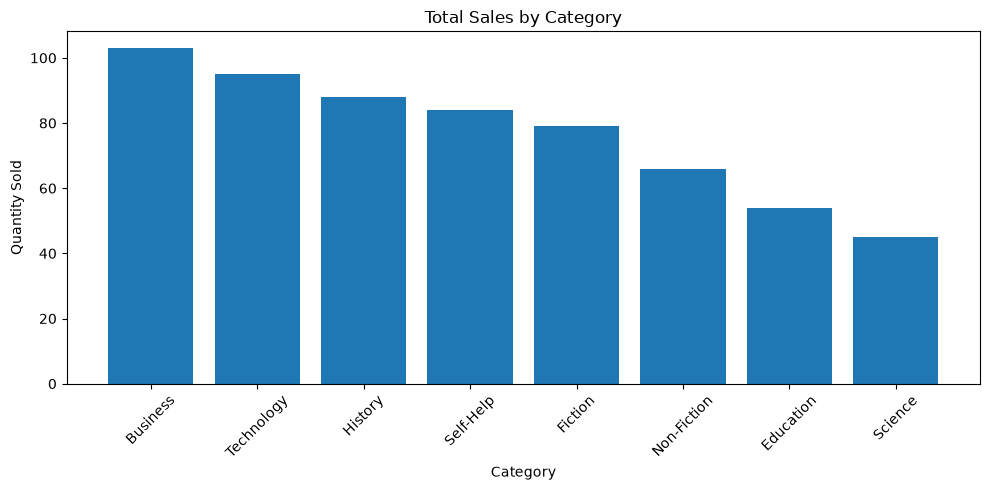

In [50]:
import matplotlib.pyplot as plt

# Calculate total quantity sold by category
sales_details = sales_df.merge(
    inventory_df[["Book_ID", "Category"]],
    on="Book_ID",
    how="left"
)

category_sales = (
    sales_details
    .groupby("Category")["Quantity_Sold"]
    .sum()
    .sort_values(ascending=False)
)

# Create Bar Chart
plt.figure(figsize=(10, 5))

plt.bar(
    category_sales.index,
    category_sales.values
)

plt.title("Total Sales by Category")
plt.xlabel("Category")
plt.ylabel("Quantity Sold")

plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

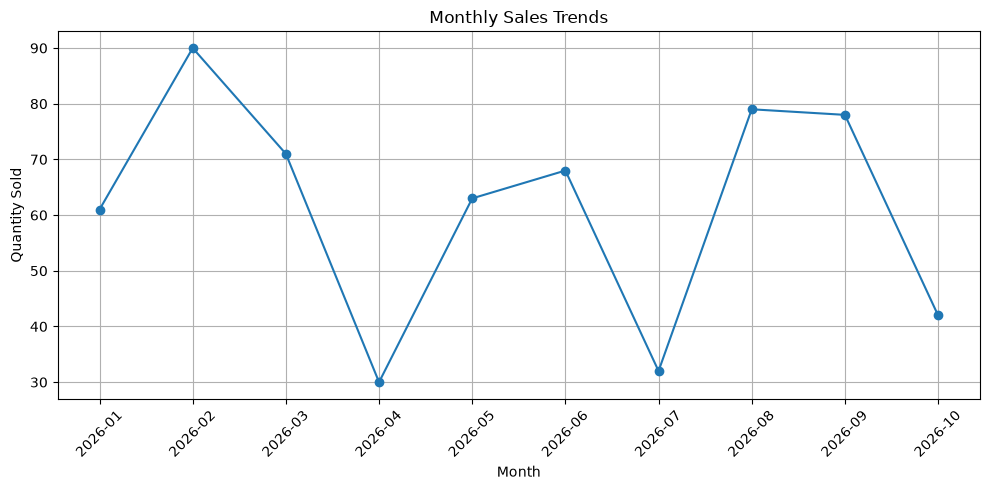

In [51]:
import matplotlib.pyplot as plt
import pandas as pd

# Convert Date column to datetime
sales_df["Date"] = pd.to_datetime(sales_df["Date"])

# Calculate monthly sales
monthly_sales = (
    sales_df
    .groupby(sales_df["Date"].dt.to_period("M"))["Quantity_Sold"]
    .sum()
)

# Convert period to string for display
monthly_sales.index = monthly_sales.index.astype(str)

# Create Line Chart
plt.figure(figsize=(10, 5))

plt.plot(
    monthly_sales.index,
    monthly_sales.values,
    marker="o"
)

plt.title("Monthly Sales Trends")
plt.xlabel("Month")
plt.ylabel("Quantity Sold")

plt.xticks(rotation=45)
plt.grid(True)

plt.tight_layout()
plt.show()

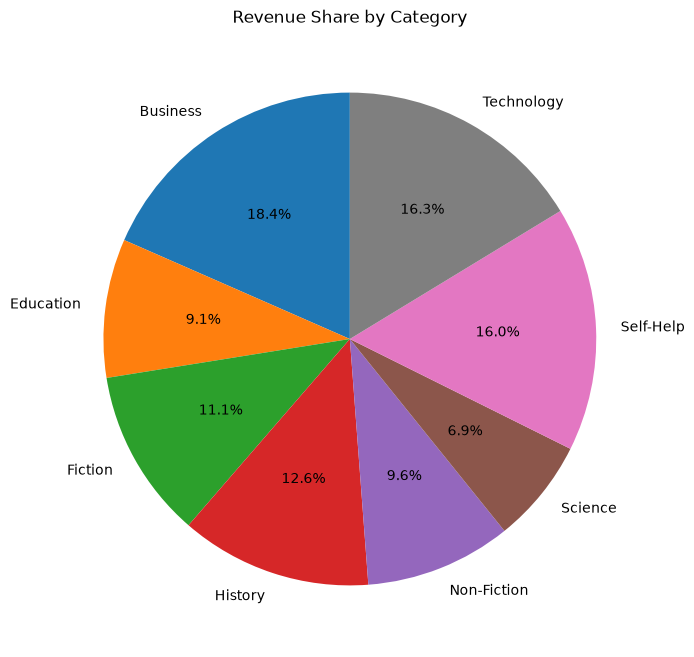

In [52]:
import matplotlib.pyplot as plt

# Combine sales and inventory data
sales_details = sales_df.merge(
    inventory_df[["Book_ID", "Category"]],
    on="Book_ID",
    how="left"
)

# Calculate revenue by category
category_revenue = (
    sales_details
    .groupby("Category")["Total_Amount"]
    .sum()
)

# Create Pie Chart
plt.figure(figsize=(8, 8))

plt.pie(
    category_revenue.values,
    labels=category_revenue.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Revenue Share by Category")

plt.show()

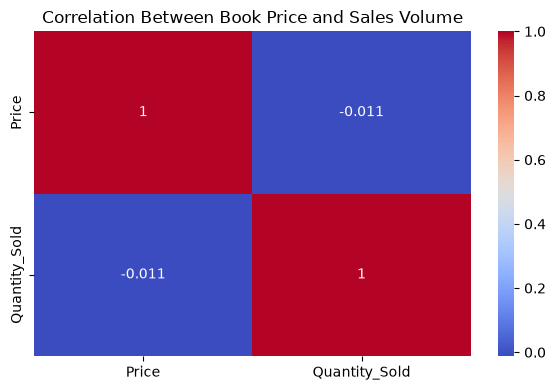

In [53]:
import matplotlib.pyplot as plt
import seaborn as sns

# Combine inventory and sales data
heatmap_data = sales_df.merge(
    inventory_df[["Book_ID", "Price"]],
    on="Book_ID",
    how="left"
)

# Select the required columns
correlation_data = heatmap_data[
    ["Price", "Quantity_Sold"]
]

# Calculate correlation
correlation = correlation_data.corr()

# Create Heatmap
plt.figure(figsize=(6, 4))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm"
)

plt.title("Correlation Between Book Price and Sales Volume")

plt.tight_layout()
plt.show()